In [1]:
import pandas as pd
from datetime import date

# Arquivos anuais de carga diária publicados pelo ONS (dados abertos, licença CC-BY)
URL = "https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/carga_energia_di/CARGA_ENERGIA_{ano}.csv"
anos = range(2010, date.today().year + 1)

partes = []
for ano in anos:
    df = pd.read_csv(URL.format(ano=ano), sep=";")
    partes.append(df)
    print(ano, df.shape)

bruto = pd.concat(partes, ignore_index=True)
bruto.to_csv("../data/raw/carga_energia_diaria.csv", index=False)
bruto.head()

2010 (1460, 4)
2011 (1460, 4)
2012 (1464, 4)
2013 (1461, 4)
2014 (1460, 4)
2015 (1460, 4)
2016 (1464, 4)
2017 (1460, 4)
2018 (1460, 4)
2019 (1460, 4)
2020 (1464, 4)
2021 (1460, 4)
2022 (1460, 4)
2023 (1460, 4)
2024 (1464, 4)
2025 (1460, 4)
2026 (1184, 4)


,id_subsistema,nom_subsistema,din_instante,val_cargaenergiamwmed
0,N,Norte,2010-01-01,3395.351667
1,NE,Nordeste,2010-01-01,6660.990833
2,S,Sul,2010-01-01,5893.170450
3,SE,Sudeste/Centro-Oeste,2010-01-01,25055.569289
4,N,Norte,2010-01-02,3417.356219


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

bruto = pd.read_csv("../data/raw/carga_energia_diaria.csv")

# 1) Datas: em 2013 o ONS gravou "2013-01-01 00:00:00"; nos outros anos, só "2013-01-01"
print("formatos de data:", bruto["din_instante"].str.len().value_counts().to_dict())
bruto["data"] = pd.to_datetime(bruto["din_instante"].str[:10])

# 2) Problemas de qualidade
print("valores vazios:", bruto["val_cargaenergiamwmed"].isna().sum())
print("linhas duplicadas (mesma região e dia):", bruto.duplicated(["id_subsistema", "data"]).sum())

limpo = (bruto.dropna(subset=["val_cargaenergiamwmed"])
              .drop_duplicates(["id_subsistema", "data"]))

# 3) Uma coluna por região e uma linha por dia
regioes = limpo.pivot(index="data", columns="nom_subsistema", values="val_cargaenergiamwmed")
regioes = regioes.asfreq("D")  # garante todos os dias do calendário
print("dias sem dado:", regioes.index[regioes.isna().any(axis=1)].strftime("%d/%m/%Y").tolist())

# 4) Carga do Brasil (SIN) = soma das 4 regiões; dias sem dado são preenchidos pela média dos vizinhos
regioes = regioes.interpolate()
regioes["SIN"] = regioes.sum(axis=1)
regioes.to_csv("../data/processed/carga_diaria.csv")
print("período:", regioes.index.min().date(), "a", regioes.index.max().date(), "|", len(regioes), "dias")
regioes.tail()

formatos de data: {10: 23100, 19: 1461}
valores vazios: 13
linhas duplicadas (mesma região e dia): 1
dias sem dado: ['01/12/2013', '01/02/2014', '09/04/2015']
período: 2010-01-01 a 2026-10-23 | 6140 dias


nom_subsistema,Nordeste,Norte,Sudeste/Centro-Oeste,Sul,SIN
data,,,,,
2026-10-19,15304.320500,9719.972333,43307.097333,13075.538458,81406.928625
2026-10-20,15978.314917,9936.471417,44769.687458,13771.785042,84456.258833
2026-10-21,15720.703208,9941.552583,45834.752042,14372.093167,85869.101000
2026-10-22,16115.441583,9872.129625,46212.332708,14987.657625,87187.561542
2026-10-23,15768.700458,10090.776458,47349.837792,14952.433333,88161.748042


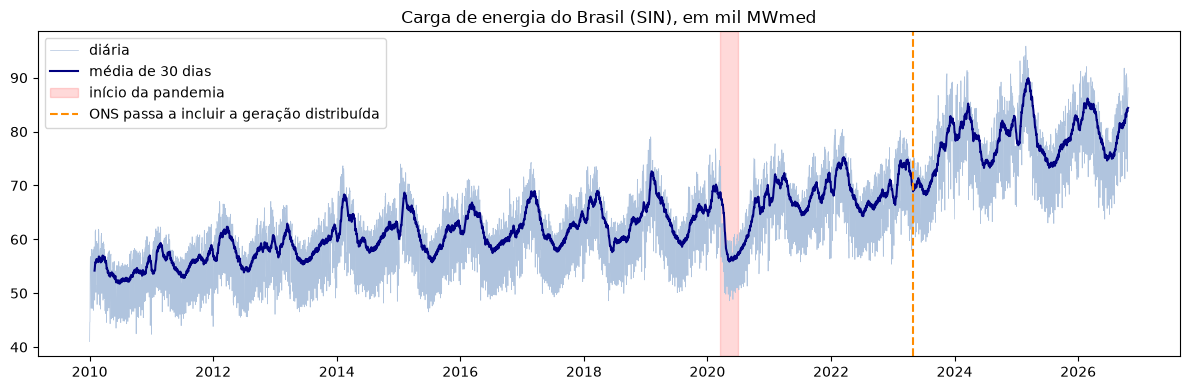

data
2019    2.1
2020   -1.8
2021    8.1
2022    0.4
2023    7.1
2024    7.1
2025    0.8
2026    1.4
Name: SIN, dtype: float64

In [3]:
sin = regioes["SIN"]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sin.index, sin / 1000, lw=0.5, color="lightsteelblue", label="diária")
ax.plot(sin.index, sin.rolling(30).mean() / 1000, color="navy", label="média de 30 dias")
ax.axvspan("2020-03-15", "2020-06-30", color="red", alpha=0.15, label="início da pandemia")
ax.axvline(pd.Timestamp("2023-04-29"), color="darkorange", ls="--",
           label="ONS passa a incluir a geração distribuída")
ax.set_title("Carga de energia do Brasil (SIN), em mil MWmed")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("../reports/figures/serie_historica.png", dpi=120)
plt.show()

# Crescimento médio por ano
media_ano = sin.groupby(sin.index.year).mean()
(media_ano.pct_change() * 100).round(1).tail(8)

C:\Users\igorb\AppData\Local\Temp\ipykernel_18844\4008708541.py:9: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  por_dia = relativo.groupby(relativo.index.dayofweek).mean()


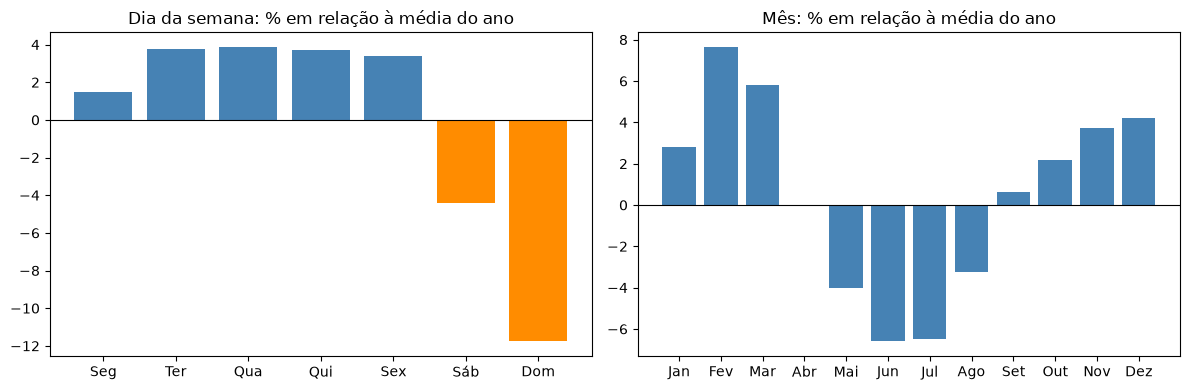

Por dia da semana (%): {'Seg': 1.5, 'Ter': 3.7, 'Qua': 3.9, 'Qui': 3.7, 'Sex': 3.4, 'Sáb': -4.4, 'Dom': -11.8}


In [4]:
# Daqui em diante: só o período com a definição atual de carga (desde 29/04/2023)
recente = sin["2023-04-29":]

nomes_dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
nomes_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

# Variação em relação à média de cada ano (remove o efeito do crescimento ao longo do tempo)
relativo = recente / recente.groupby(recente.index.year).transform("mean") * 100 - 100
por_dia = relativo.groupby(relativo.index.dayofweek).mean()
por_mes = relativo.groupby(relativo.index.month).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(nomes_dias, por_dia, color=["steelblue"] * 5 + ["darkorange"] * 2)
ax1.set_title("Dia da semana: % em relação à média do ano")
ax2.bar(nomes_meses, por_mes.reindex(range(1, 13)), color="steelblue")
ax2.set_title("Mês: % em relação à média do ano")
for ax in (ax1, ax2):
    ax.axhline(0, color="black", lw=0.8)
plt.tight_layout()
plt.savefig("../reports/figures/sazonalidade.png", dpi=120)
plt.show()

print("Por dia da semana (%):", por_dia.round(1).set_axis(nomes_dias).to_dict())

In [5]:
import sys
sys.path.append("..")
from src.feriados import calendario

cal = calendario(recente.index).set_index("data")

# Efeito de cada feriado: carga do dia x média do mesmo dia da semana nas 2 semanas antes e 2 depois
def efeito(dia):
    vizinhos = [dia + pd.Timedelta(weeks=k) for k in (-2, -1, 1, 2)]
    vizinhos = [v for v in vizinhos if v in recente.index and pd.isna(cal.at[v, "nome_feriado"])]
    return (recente[dia] / recente[vizinhos].mean() - 1) * 100

especiais = cal[cal["nome_feriado"].notna()]
especiais = especiais.assign(efeito_pct=[efeito(d) for d in especiais.index])
tabela = (especiais.groupby("nome_feriado")["efeito_pct"].mean()
                   .sort_values().round(1))
tabela

nome_feriado
Confraternização Universal   -21.4
Natal                        -19.1
Sexta-feira Santa            -14.9
Dia do Trabalho              -11.4
Véspera de Ano Novo           -9.7
Tiradentes                    -9.4
Corpus Christi                -9.4
Independência                 -9.2
Véspera de Natal              -7.8
Consciência Negra             -6.4
Nossa Senhora Aparecida       -6.2
Carnaval (terça)              -4.9
Proclamação da República      -4.5
Finados                       -4.4
Carnaval (segunda)            -3.5
Quarta-feira de Cinzas        -0.2
Name: efeito_pct, dtype: float64